# PyRainCloud 0.1.0 — демонстрация

Rain cloud plot = **облако** плотности (half-violin) + **ящик** (box plot) + **дождь** (сами наблюдения).
Вся библиотека — одна функция: `rc.raincloud(data, x, y)`.

Ноутбук проходит путь пользователя из инструкции: установка → данные → базовый график → настройка → подписи и экспорт → ошибки.

In [1]:
%config InlineBackend.figure_format = "retina"
from pathlib import Path

import pyraincloud as rc

IMAGES = Path("../docs/images")  # графики для README и инструкции
print("PyRainCloud", rc.__version__)
print(rc.raincloud.__doc__.split("Parameters")[0].strip())

PyRainCloud 0.1.0
Draw a rain cloud plot: half-violin ("cloud") + box plot + jittered raw points ("rain").


## 1. Данные

«Длинный» формат: одна строка — одно наблюдение. Колонка `group` — группа, `reaction_time` — время реакции, мс.

In [2]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
df = pd.DataFrame({
    "group": ["Control"] * 30 + ["Treatment A"] * 30 + ["Treatment B"] * 30,
    "reaction_time": np.concatenate([rng.normal(500, 50, 30),
                                     rng.normal(450, 60, 30),
                                     rng.normal(480, 55, 30)]),
})
df.sample(6, random_state=1)

,group,reaction_time
58,Treatment A,398.050133
78,Treatment B,514.407472
43,Treatment A,463.929679
55,Treatment A,411.667329
87,Treatment B,480.687177
74,Treatment B,487.833415


## 2. Базовый график — одна команда

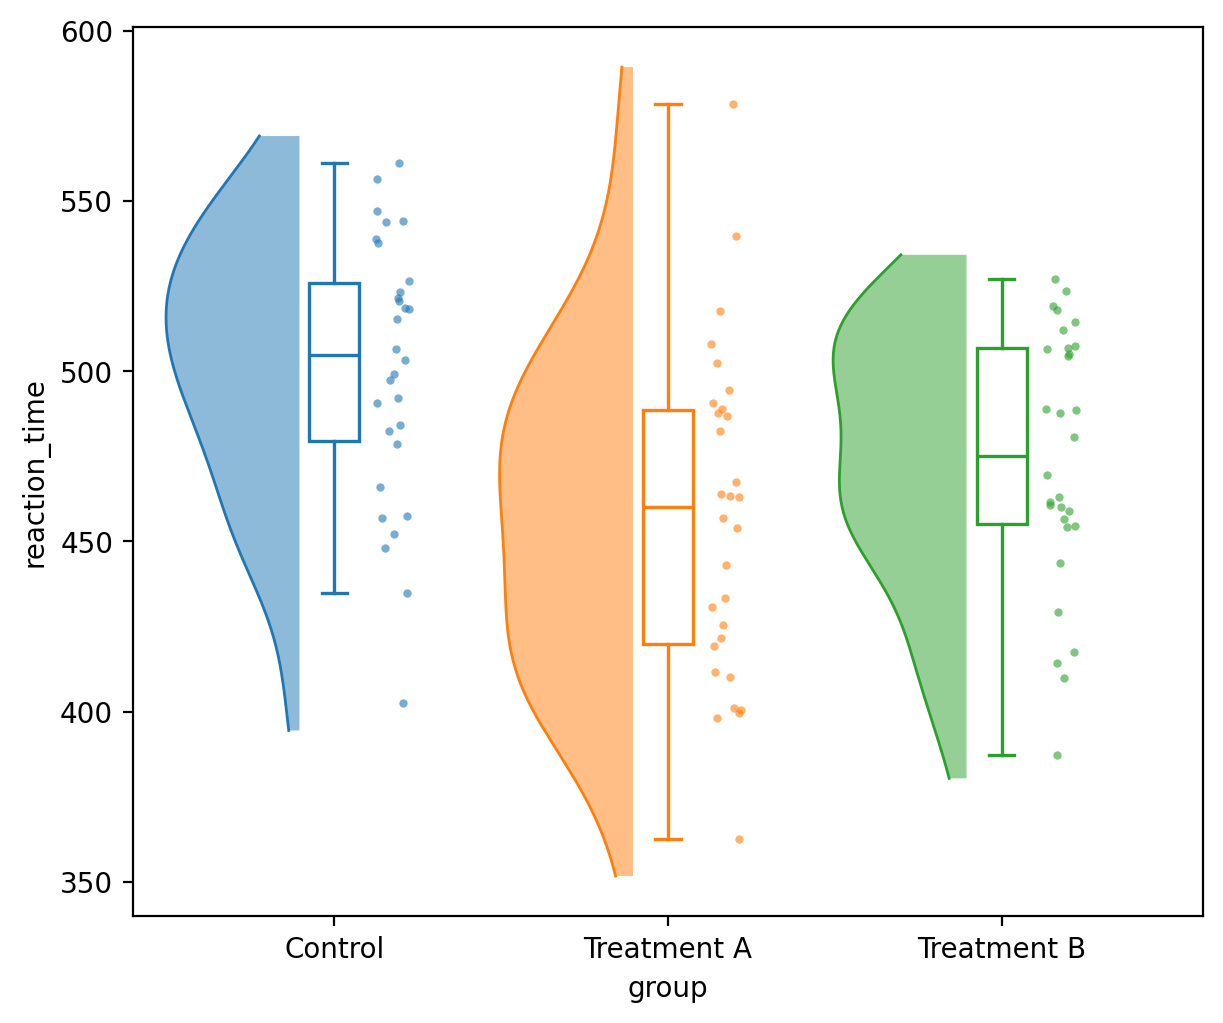

In [3]:
fig, ax = rc.raincloud(data=df, x="group", y="reaction_time", random_state=0)
fig.savefig(IMAGES / "01_basic.png", dpi=150)

## 3. Настройка внешнего вида

Палитра, ориентация, прозрачность и размеры слоёв, отключение ящиков или точек.

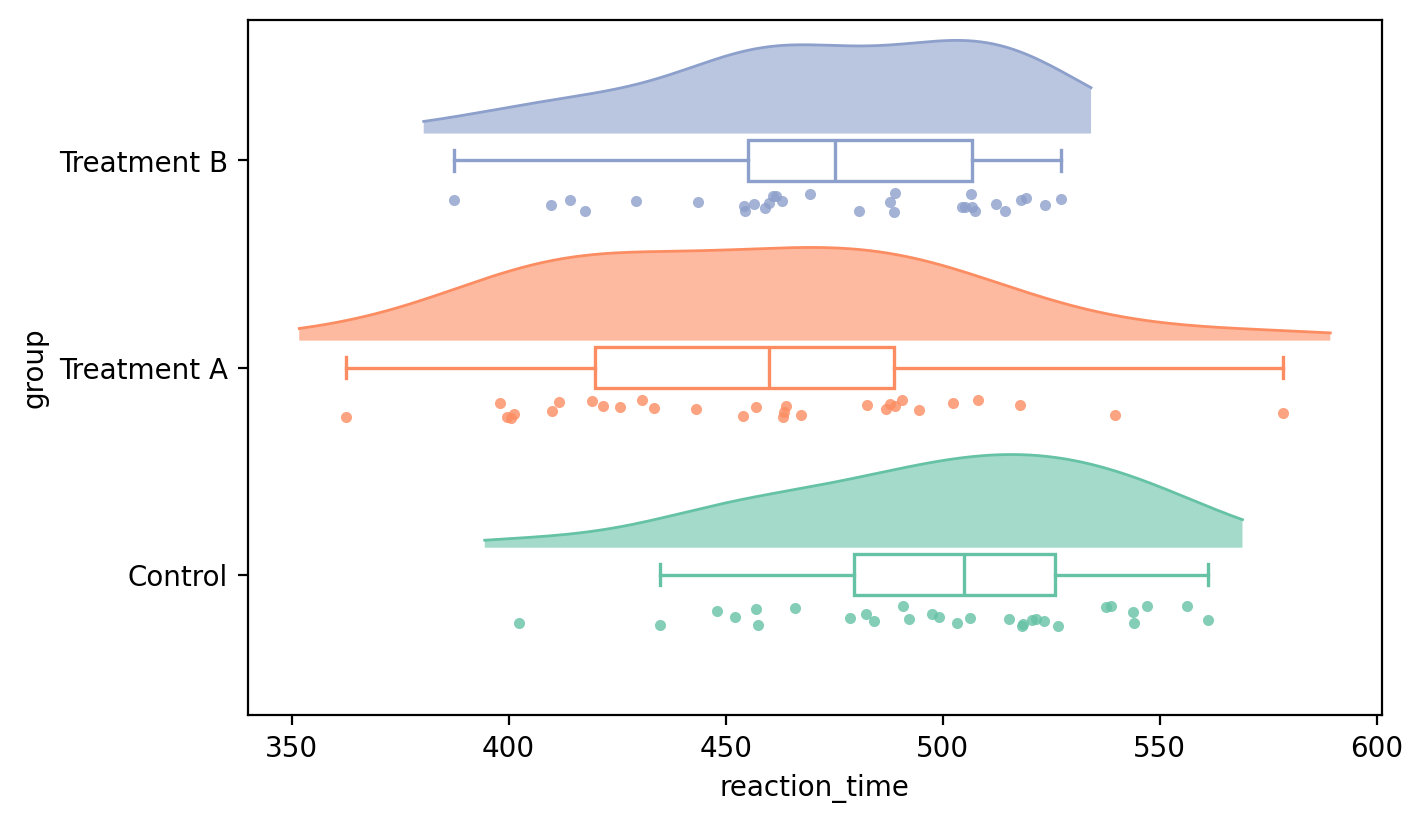

In [4]:
palette = ["#66c2a5", "#fc8d62", "#8da0cb"]
fig, ax = rc.raincloud(
    data=df, x="group", y="reaction_time",
    orient="h", palette=palette,
    cloud_alpha=0.6, cloud_width=0.9,
    point_size=4, point_alpha=0.8, box_width=0.2,
    random_state=0,
)
fig.savefig(IMAGES / "02_custom_horizontal.png", dpi=150)

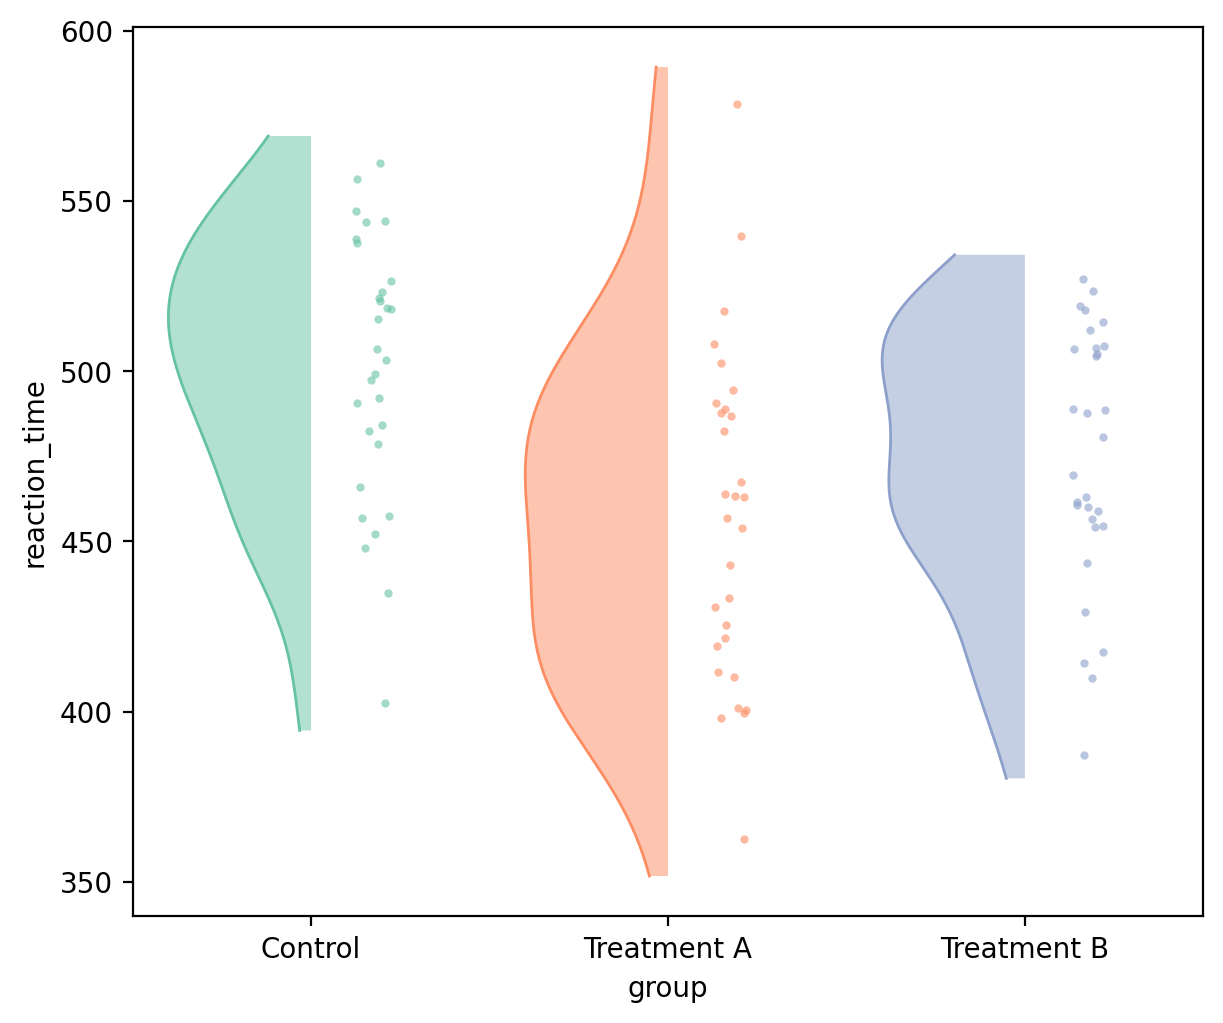

In [5]:
fig, ax = rc.raincloud(data=df, x="group", y="reaction_time",
                       palette=palette, add_boxes=False, random_state=0)
fig.savefig(IMAGES / "02b_no_boxes.png", dpi=150)

## 4. Подписи, отметка значимости и экспорт

Функция возвращает обычные `fig, ax` matplotlib — дальше работает весь привычный API.

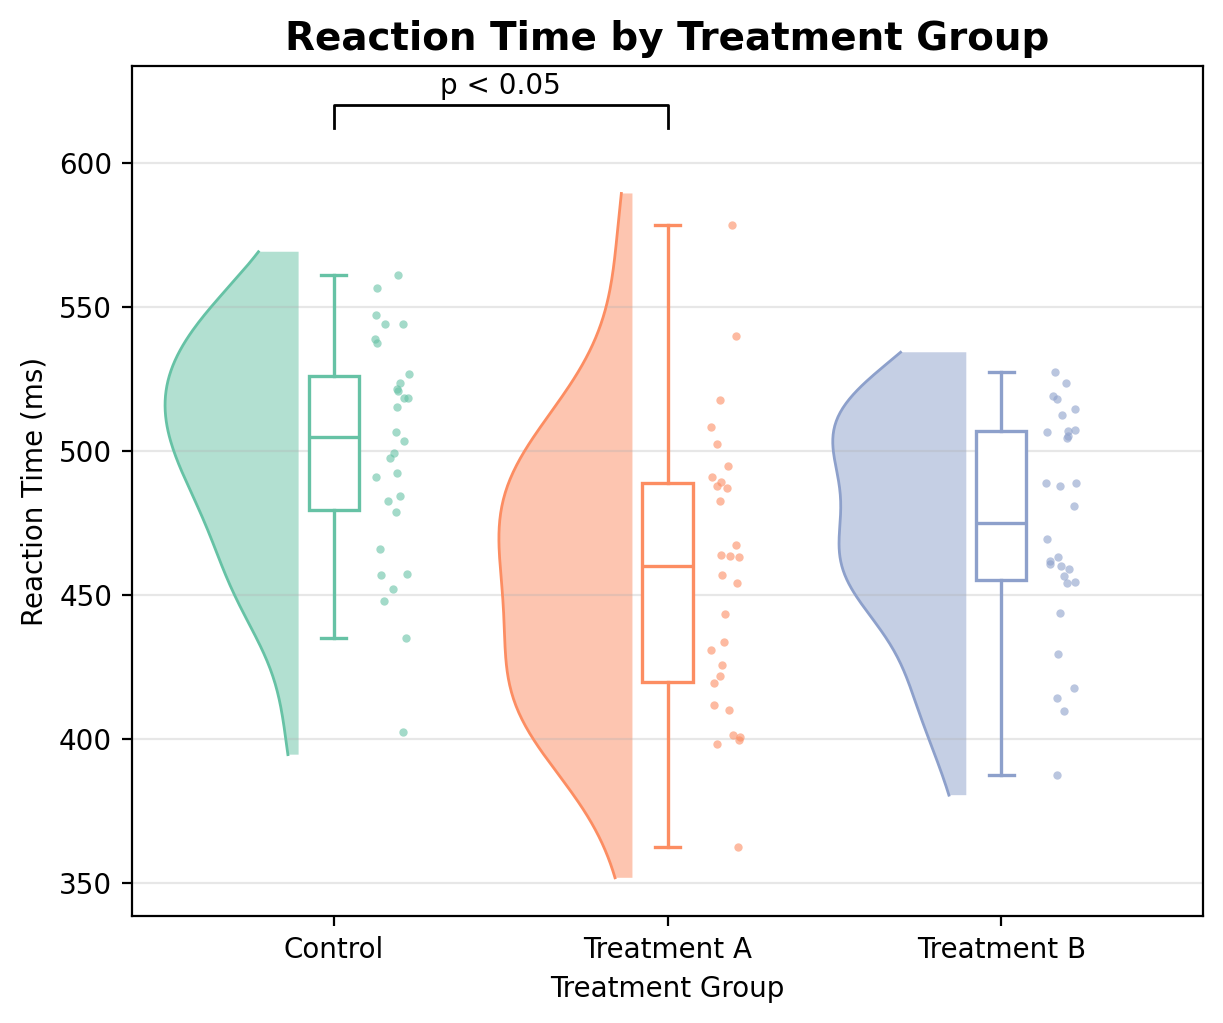

In [6]:
fig, ax = rc.raincloud(data=df, x="group", y="reaction_time",
                       palette=palette, random_state=0)
ax.set_title("Reaction Time by Treatment Group", fontsize=14, fontweight="bold")
ax.set_xlabel("Treatment Group")
ax.set_ylabel("Reaction Time (ms)")
ax.plot([0, 0, 1, 1], [612, 620, 620, 612], color="black", linewidth=1)
ax.annotate("p < 0.05", xy=(0.5, 622), ha="center", va="bottom")
ax.grid(axis="y", alpha=0.3)
fig.savefig(IMAGES / "03_annotated.png", dpi=150)

In [7]:
import os

for name in ("raincloud_plot.pdf", "raincloud_plot.png"):
    fig.savefig(name, dpi=300, bbox_inches="tight")
    print(f"{name:20s} {os.path.getsize(name) / 1024:7.1f} KB")

raincloud_plot.pdf      30.6 KB
raincloud_plot.png     137.1 KB


## 5. Несколько графиков на одной фигуре

Оси создаются заранее и передаются через `ax=`.

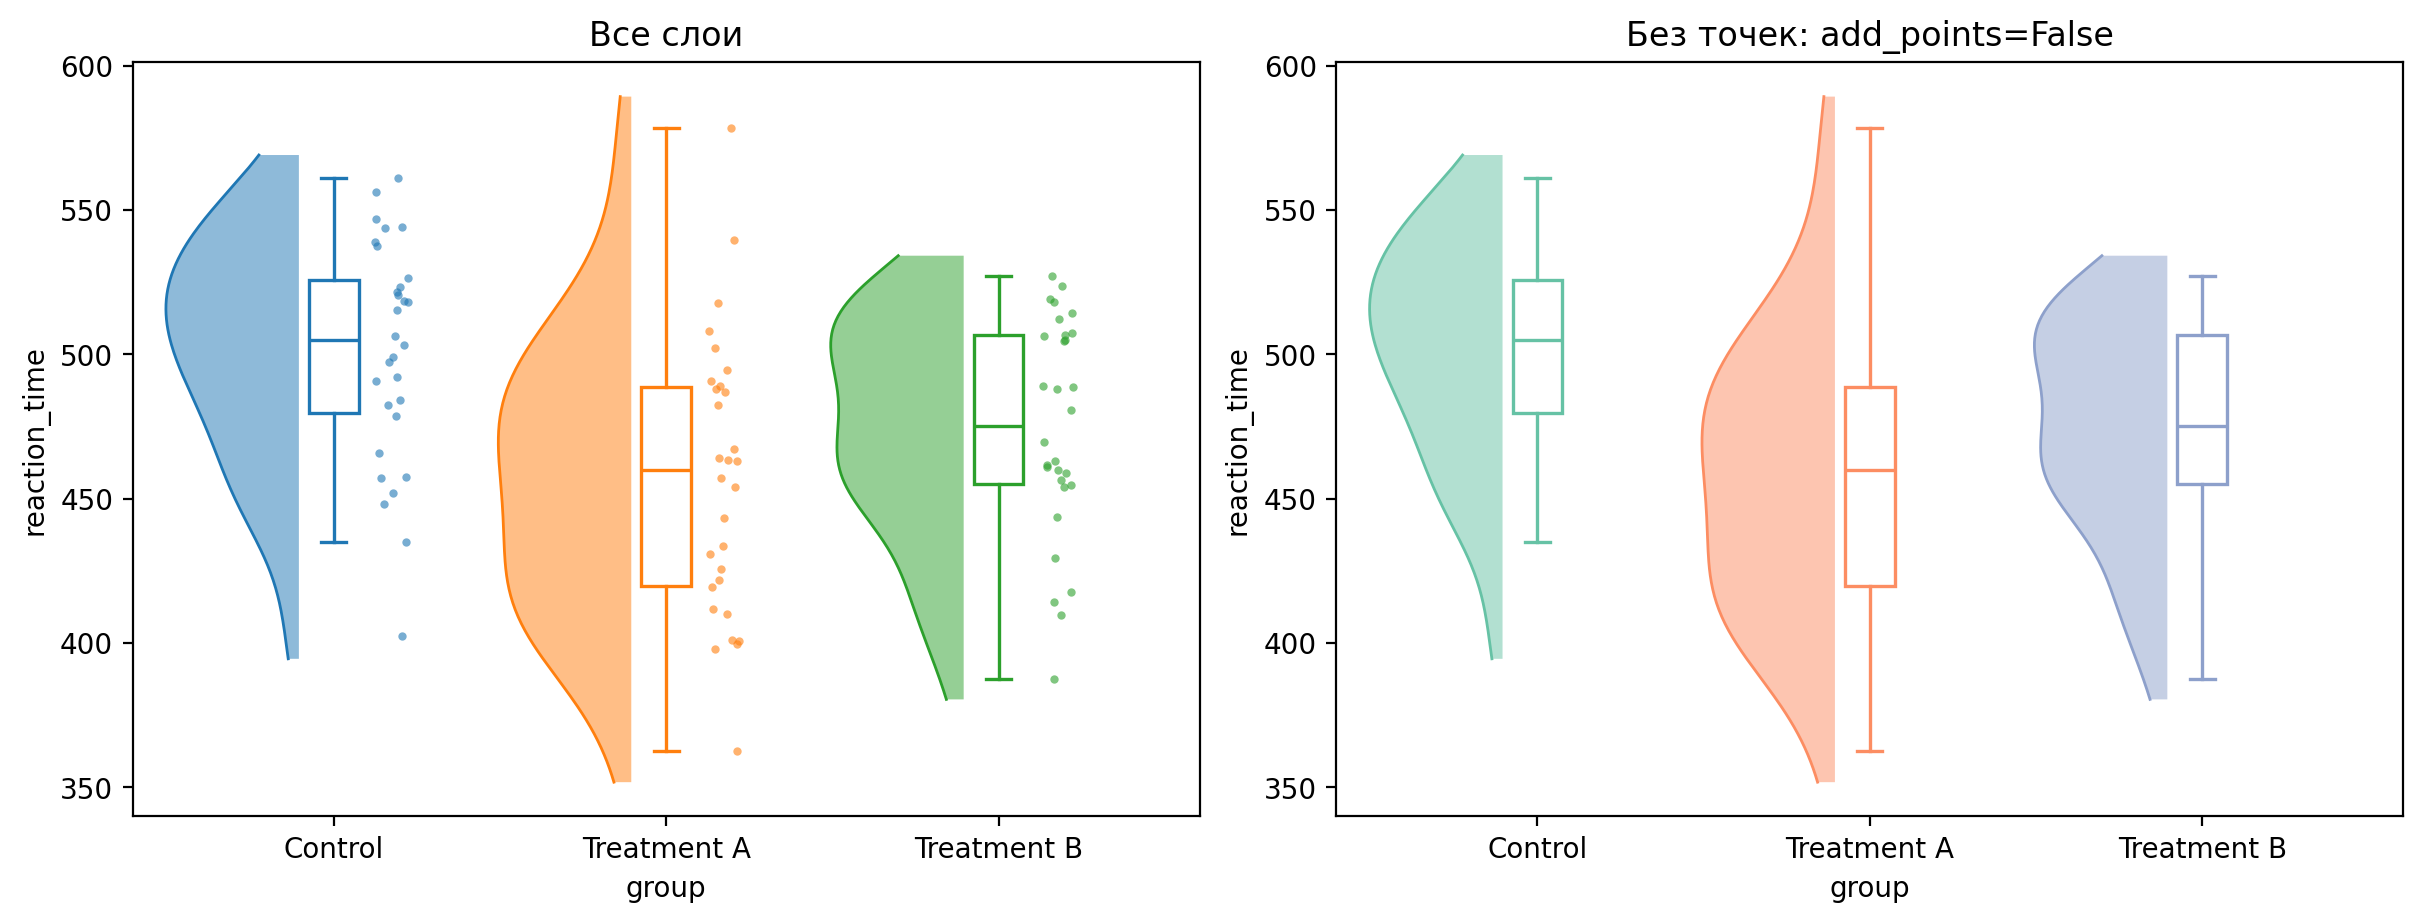

In [8]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
rc.raincloud(data=df, x="group", y="reaction_time", ax=ax1, random_state=0)
rc.raincloud(data=df, x="group", y="reaction_time", ax=ax2, palette=palette, add_points=False)
ax1.set_title("Все слои")
ax2.set_title("Без точек: add_points=False")
fig.savefig(IMAGES / "04_subplots.png", dpi=150)

## 6. Если что-то пошло не так

Ошибки сообщают, что именно исправить; некритичные проблемы с данными — предупреждения `RaincloudWarning`.

In [9]:
fig, ax = rc.raincloud(data=df, x="condition", y="reaction_time")

ValueError: Column 'condition' not found in data

In [10]:
fig, ax = rc.raincloud(
    data=df, x="group", y="reaction_time", palette=["#66c2a5", "#fc8d62"]
)

ValueError: palette has 2 colour(s) but data has 3 group(s); the palette must cover all groups

/tmp/ipykernel_199301/2330612626.py:3: RaincloudWarning: Group 'Control': dropped 2 NaN value(s) in column 'reaction_time'
  fig, ax = rc.raincloud(data=df_nan, x="group", y="reaction_time", random_state=0)
/tmp/ipykernel_199301/2330612626.py:3: RaincloudWarning: Group 'Treatment A': dropped 1 NaN value(s) in column 'reaction_time'
  fig, ax = rc.raincloud(data=df_nan, x="group", y="reaction_time", random_state=0)


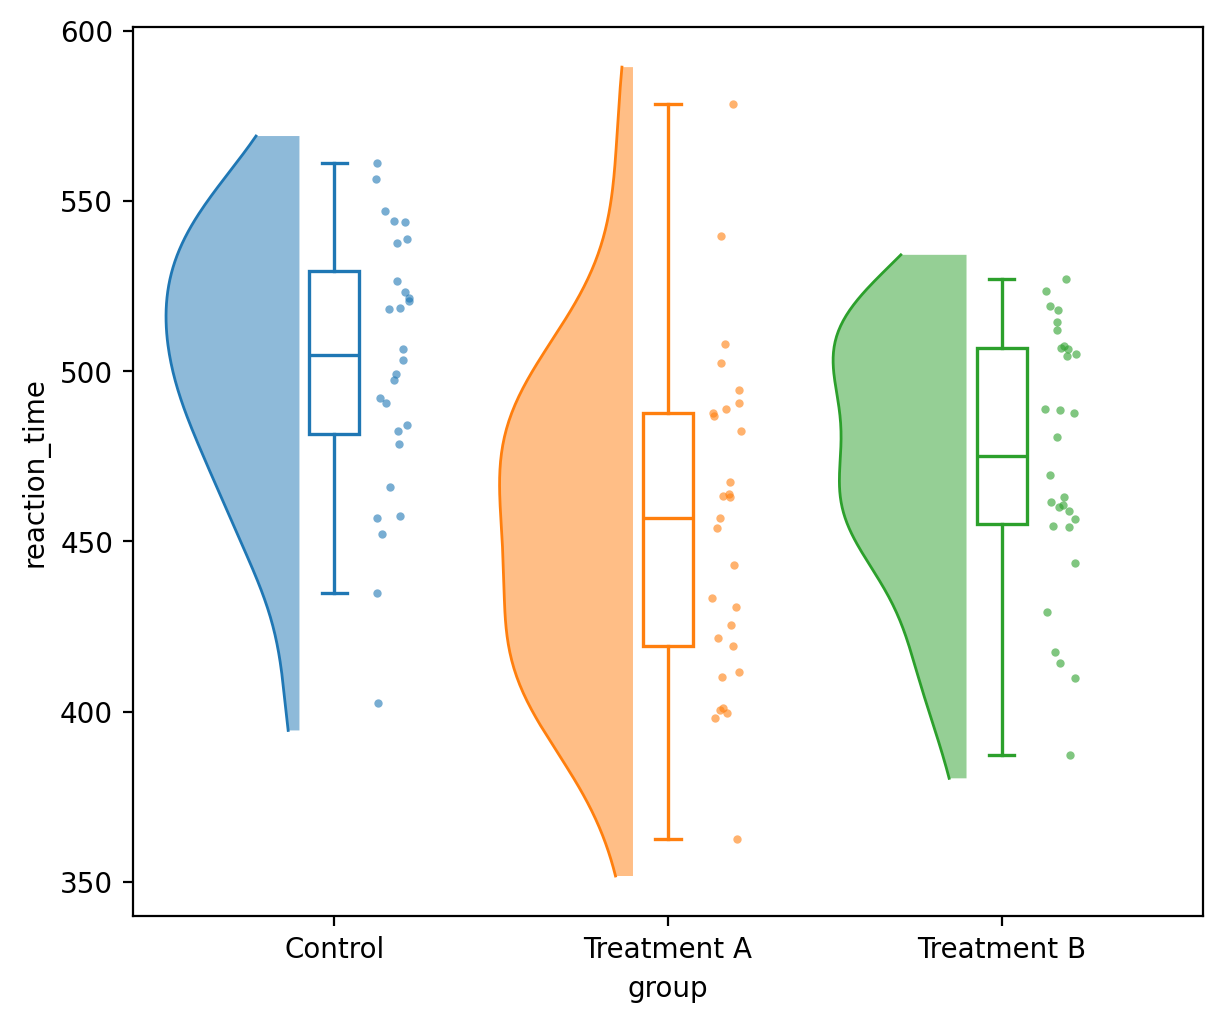

In [11]:
df_nan = df.copy()
df_nan.loc[[0, 1, 35], "reaction_time"] = np.nan
fig, ax = rc.raincloud(data=df_nan, x="group", y="reaction_time", random_state=0)